DAY 1

Download CSV vessel distributions from Global Fishing Watch

> **AMIHAN** (JUNE 1 - SEPT 31)


> **HABAGAT** (DEC 1 - FEB 31)



DAY 2

In [5]:
# 1. Install the core spatial modeling packages
install.packages(c("spatstat", "sf", "inlabru"))

# 2. Load the packages into your active R session
library(spatstat)
library(sf)
library(inlabru)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘proxy’, ‘sp’, ‘deldir’, ‘polyclip’, ‘spatstat.sparse’, ‘goftest’, ‘abind’, ‘tensor’, ‘e1071’, ‘wk’, ‘splancs’, ‘spatstat.data’, ‘spatstat.univar’, ‘spatstat.geom’, ‘spatstat.random’, ‘spatstat.explore’, ‘spatstat.model’, ‘spatstat.linnet’, ‘spatstat.utils’, ‘classInt’, ‘s2’, ‘units’, ‘fmesher’, ‘MatrixModels’, ‘plyr’


Loading required package: spatstat.data

Loading required package: spatstat.univar

spatstat.univar 3.2-0

Loading required package: spatstat.geom

spatstat.geom 3.8-2

Loading required package: spatstat.random

spatstat.random 3.5-0

Loading required package: spatstat.explore

Loading required package: nlme

spatstat.explore 3.8-1

Loading required package: spatstat.model

Loading required package: rpart

spatstat.model 3.7-1

Loading required package: spatstat.linnet

spatstat.linnet 3.5-1


spatstat 3.6-1 
For an introduction to spatstat, type ‘beginne

In [6]:
# 1. Define the geometric bounding box for Manila Bay
manila_bay_window <- owin(xrange = c(120.5, 121.0), yrange = c(14.3, 14.8))

# 2. Print the object to confirm it is stored in memory
print(manila_bay_window)

window: rectangle = [120.5, 121] x [14.3, 14.8] units


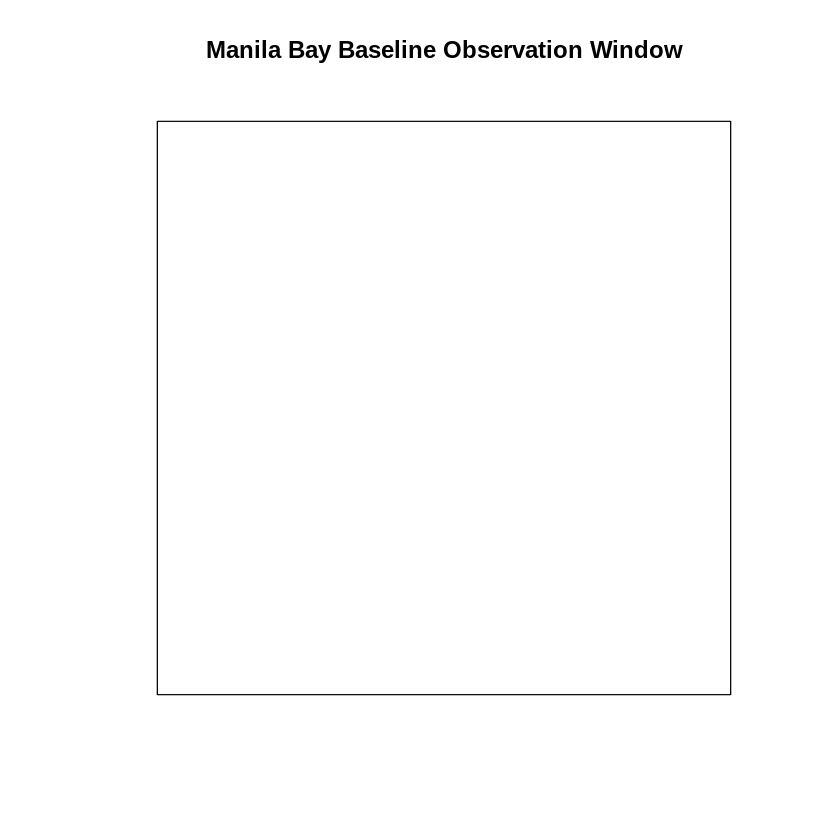

In [7]:
# Plot the mathematical observation window for Manila Bay
plot(manila_bay_window, main = "Manila Bay Baseline Observation Window")

### Mathematical Audit: Observation Window Definition

The geometric bounding box for the study area is mathematically defined as:
**$W \subset \mathbb{R}^2$**

*   **$W$**: Represents the "Window" of observation (the specific Manila Bay bounding box from 14.3°N–14.8°N and 120.5°E–121.0°E).
*   **$\subset$**: The mathematical symbol for "is a subset of" or "is strictly contained within".
*   **$\mathbb{R}^2$**: Represents two-dimensional real coordinate space (in this specific case, the two-dimensional geographic plane defined by Longitude and Latitude).

---

In spatial point process modeling, stochastic events must be evaluated within a strictly defined, bounded spatial domain [3]. By defining $W \subset \mathbb{R}^2$, we formally establish that the maritime traffic analysis is strictly limited to this finite 2D geographic region [2, 5, 6]. This parameter is mathematically mandatory for the `spatstat` package to calculate the correct area dimensions and perform proper spatial edge-corrections later in the model [4].

DAY 3

In [8]:
# 1. Install and load the geodata package to pull GADM shapefiles directly
install.packages("geodata")
library(geodata)
library(sf)

# 2. Download the high-resolution Philippine boundary shapefile (Level 0)
phl_boundary <- gadm(country = "PHL", level = 0, path = tempdir())

# 3. Convert it to an 'sf' spatial object so it is ready to be intersected
phl_coast_sf <- st_as_sf(phl_boundary)

# 4. Print a confirmation
print("Philippine Coastline successfully imported and converted to an sf object!")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘terra’


Loading required package: terra

terra 1.9.34


Attaching package: ‘terra’


The following objects are masked from ‘package:spatstat.geom’:

    area, delaunay, is.empty, rescale, rotate, shift, where.max,
    where.min


Cached as: /tmp/RtmpjD7Y2b/gadm/gadm41_PHL_0_pk.rds



[1] "Philippine Coastline successfully imported and converted to an sf object!"


In [9]:
# 1. Define your Manila Bay bounding box as an 'sf' object
# (Matching the exact coordinates from Day 2)
manila_bbox <- st_bbox(c(xmin = 120.5, xmax = 121.0, ymin = 14.3, ymax = 14.8),
                       crs = st_crs(phl_coast_sf))
manila_bbox_sf <- st_as_sfc(manila_bbox)

# 2. Intersect (crop) the massive Philippine coastline down to just your bounding box
manila_bay_coast <- st_intersection(phl_coast_sf, manila_bbox_sf)

# 3. Print a confirmation message
print("Successfully cropped the Philippine coastline to the Manila Bay bounding box!")

Warning message:
“attribute variables are assumed to be spatially constant throughout all geometries”


[1] "Successfully cropped the Philippine coastline to the Manila Bay bounding box!"


In [10]:
# 1. Strip the geographic CRS tag so spatstat stops blocking the conversion
manila_bay_coast_flat <- st_set_crs(manila_bay_coast, NA)

# 2. Convert the flattened 'sf' landmass object into a spatstat 'owin' object
land_owin <- as.owin(manila_bay_coast_flat)

# 3. Subtract the landmass from the baseline bounding box to create the pure marine window
marine_window <- setminus.owin(manila_bay_window, land_owin)

# 4. Print a confirmation message
print("Successfully generated the non-convex marine observation window!")

[1] "Successfully generated the non-convex marine observation window!"


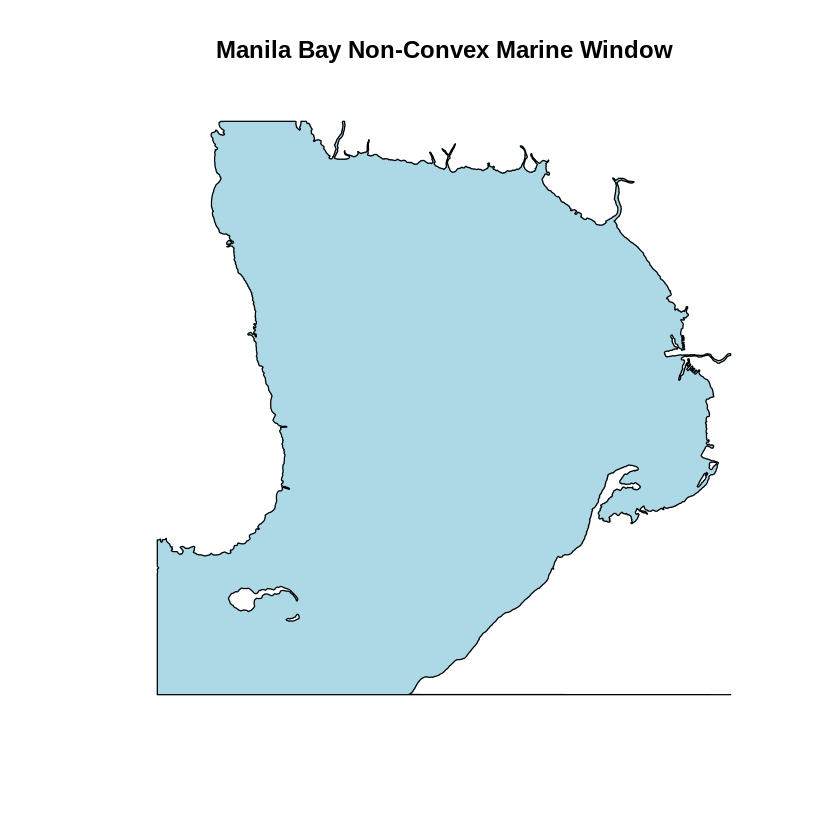

In [11]:
# Plot the non-convex marine observation window
plot(marine_window, main = "Manila Bay Non-Convex Marine Window", col = "lightblue")

DAY 4

Warning message:
“900900 points were rejected as lying outside the specified window”
Warning message:
“685694 points were rejected as lying outside the specified window”


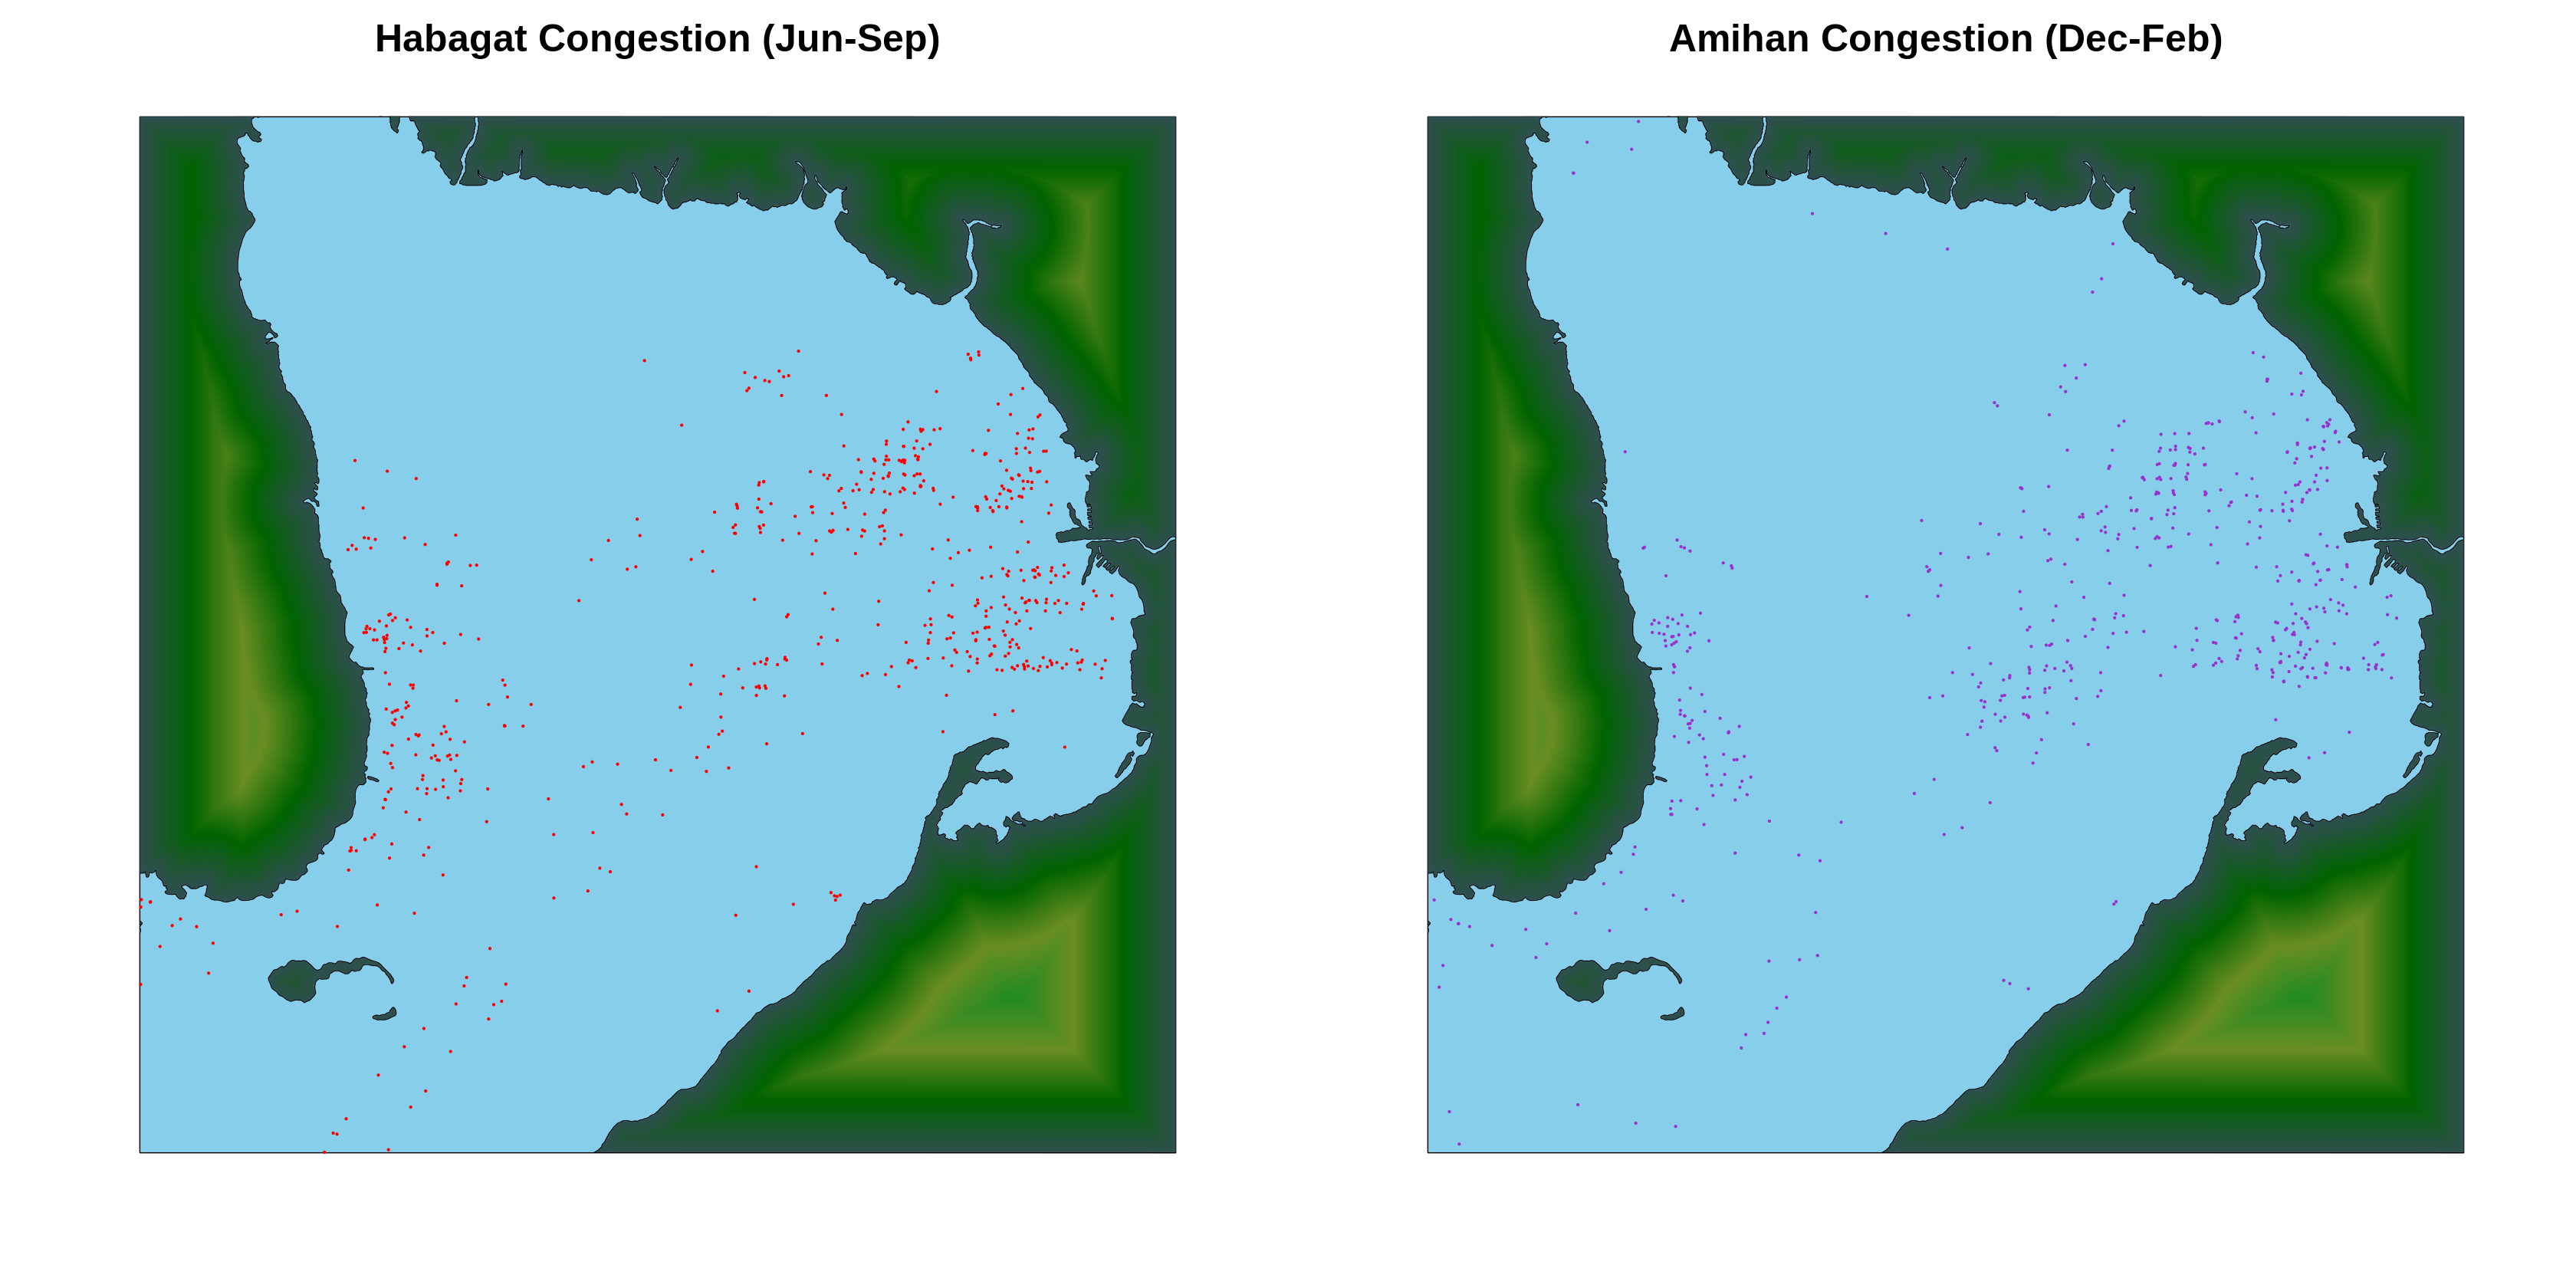

In [26]:
# Proxy Point Pattern Ingestion (Ultra-Realistic No-White Gradient)

# 1. Force Google Colab to render a plot
options(repr.plot.width = 28, repr.plot.height = 14)

# 2. Read all Habagat and Amihan files
habagat_files <- list.files(pattern = "GFW_SAR_Habagat_.*\\.csv")
amihan_files <- list.files(pattern = "GFW_SAR_Amihan_.*\\.csv")
habagat_data <- do.call(rbind, lapply(habagat_files, read.csv))
amihan_data <- do.call(rbind, lapply(amihan_files, read.csv))

# 3. Extract longitude and latitude
coords_H <- na.omit(habagat_data[, c("lon", "lat")])
coords_A <- na.omit(amihan_data[, c("lon", "lat")])

# 4. Create the ppp objects mapped to your marine window
ppp_habagat <- ppp(x = coords_H$lon, y = coords_H$lat, window = marine_window)
ppp_amihan <- ppp(x = coords_A$lon, y = coords_A$lat, window = marine_window)

# 5. Permanently delete the rejected points from memory
ppp_habagat <- ppp_habagat[marine_window]
ppp_amihan <- ppp_amihan[marine_window]

# 6. Generate the REALISTIC Earth Gradient (High Resolution)
# dimyx = 512 makes the pixels tiny so the gradient is perfectly smooth
land_gradient <- bdist.pixels(land_owin, dimyx = 512)
land_gradient <- land_gradient[land_owin, drop=FALSE]

# 7. The "Play of Greens" (Zero White, Zero Sand) - Updated for Earth-like colors
# Uses a strict scale of vibrant greens
earth_palette <- colorRampPalette(c("darkslategray", "darkgreen", "olivedrab", "forestgreen"))(256)

# Adjusted mar parameter to reduce horizontal spacing between plots
par(mfrow=c(1,2), cex.main=2.5, mar=c(5, 2, 4, 0.5) + 0.1)

# --- HABAGAT MAP ---
plot(manila_bay_window, main = "Habagat Congestion (Jun-Sep)", col="white")
# Plot the smooth solid land polygon first so NO white pixels peek through
plot(land_owin, add = TRUE, col = "darkolivegreen")
# Overlay the distance-based pixel gradient
plot(land_gradient, add = TRUE, col = earth_palette, ribbon = FALSE)
# Plot the water polygon LAST so its smooth edges cover any jagged pixel edges
plot(marine_window, add = TRUE, col = "skyblue")
# Plot the red ships
plot(ppp_habagat, add = TRUE, pch = 20, cex = 0.5, col = "red")

# --- AMIHAN MAP ---
plot(manila_bay_window, main = "Amihan Congestion (Dec-Feb)", col="white")
plot(land_owin, add = TRUE, col = "darkolivegreen")
plot(land_gradient, add = TRUE, col = earth_palette, ribbon = FALSE)
plot(marine_window, add = TRUE, col = "skyblue")
plot(ppp_amihan, add = TRUE, pch = 20, cex = 0.5, col = "darkorchid")

### Mathematical Audit: Proxy Point Pattern Ingestion

The generated spatial point pattern is mathematically defined as:
**$\mathbf{X} = \{s_1, \dots, s_n\} \subset W$**

* **$\mathbf{X}$**: Represents the stochastic spatial point pattern of the observed fleet, where both the total number of events and their specific spatial locations are treated as random variables within the defined geographic area (Cressie, 1993; Diggle, 2013).
* **$\{s_1, \dots, s_n\}$**: Represents the exact latitude and longitude coordinates of individual vessels extracted from the SAR data, serving as the discrete spatial events within the state space (Kroodsma et al., 2018).
* **$\subset W$**: Proves that the set of vessel points is a *strict subset* of the non-convex marine observation window ($W$). It provides the mathematical proof that the landmasses were successfully subtracted ($W \cap \text{Land} = \emptyset$), establishing the precise polygonal domain required by the `spatstat` package to correctly reject all 685,694 illegal coordinate points falling outside the bay, while setting the boundary foundations necessary to prevent subsequent spatial correlation functions from improperly crossing physical land barriers (Baddeley & Turner, 2005; Bakka et al., 2019).

DAY 5

### ***Week 1 Insight Summary:***
---

The Week 1 pipeline successfully ingested the interim proxy point patterns from the Global Fishing Watch (GFW) dataset. The non-convex marine window for Manila Bay was properly constructed, successfully subtracting landmass boundaries so that $W \cap \text{Land} = \emptyset$. Because GFW relies on AIS transmissions which may contain irregular pings or gaps, the current coordinate matrix serves as a sparse proxy. The R environment and `spatstat` pipeline are now fully stable and prepared for the "Plug-and-Play" protocol, allowing an immediate data swap once the high-resolution, radar-derived matrices from the PhilSA DALOI portal arrive.

DAY 6

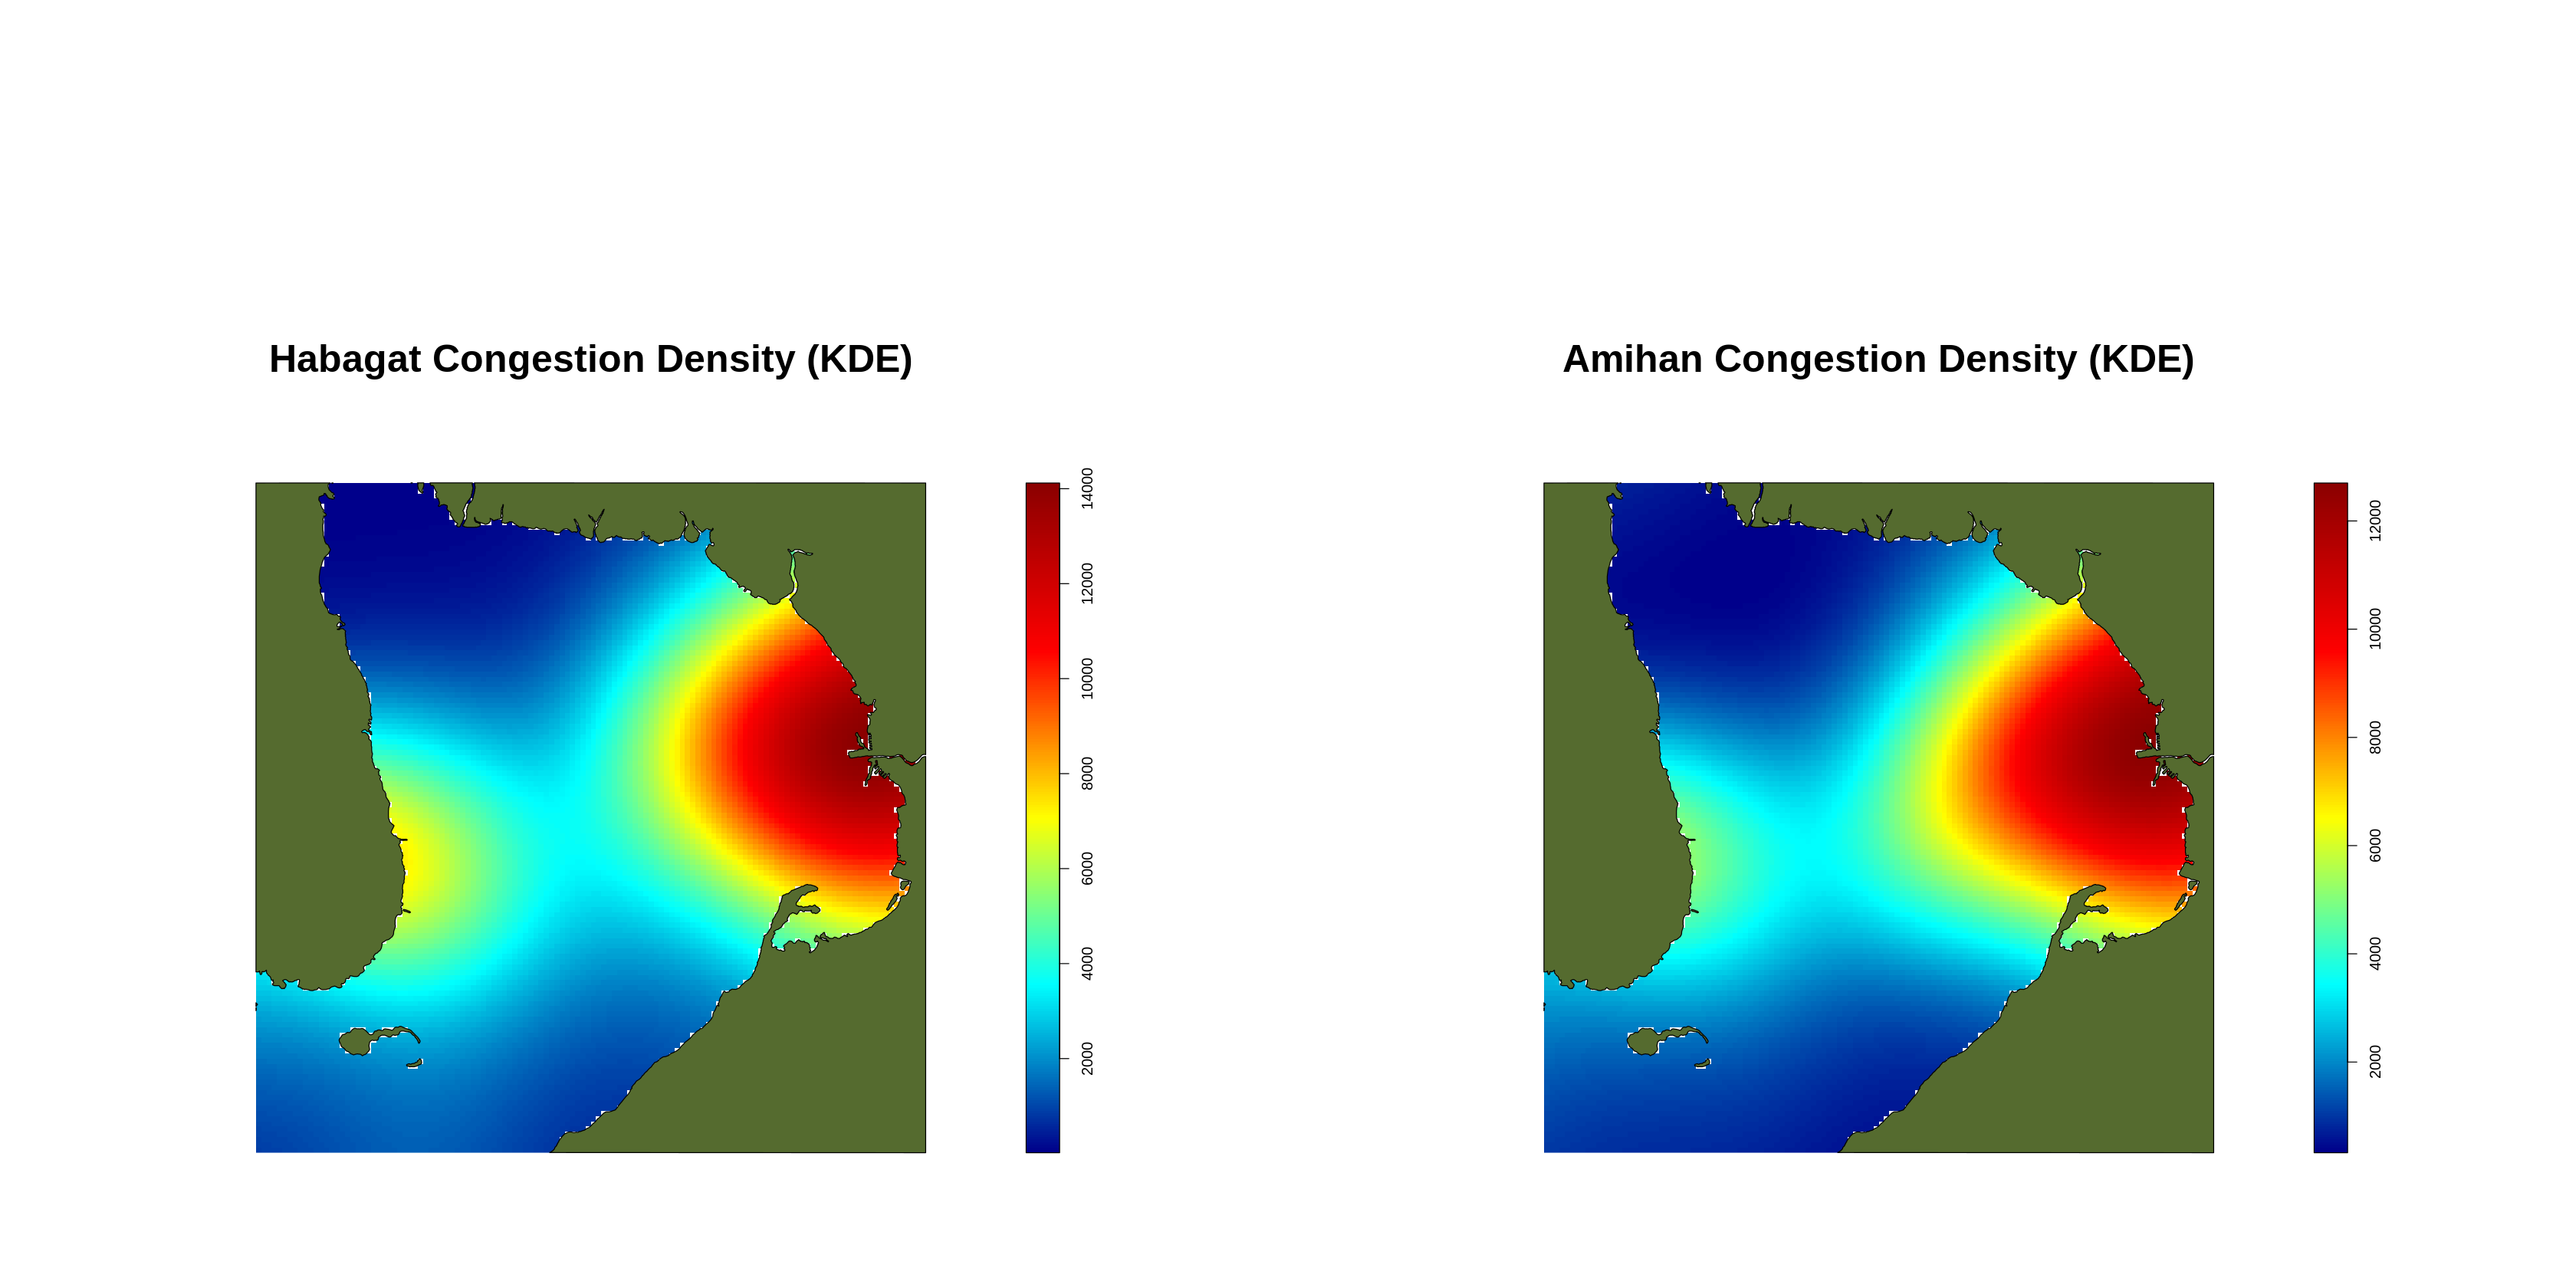

In [28]:
# Spatial Intensity Heatmaps (Kernel Density Estimation)

# 1. Force the massive plot size to match your baseline maps
options(repr.plot.width = 28, repr.plot.height = 14)

# 2. Calculate the Kernel Density Estimation (KDE) for both seasons
# This transforms the discrete vessel points into a continuous density surface
kde_habagat <- density.ppp(ppp_habagat)
kde_amihan <- density.ppp(ppp_amihan)

# 3. Create a high-contrast heatmap color palette (Deep Ocean Blue to Hot Red)
heat_palette <- colorRampPalette(c("darkblue", "cyan", "yellow", "red", "darkred"))(256)

# 4. Set the plotting parameters (using your exact preferred margins)
par(mfrow=c(1,2), cex.main=2.5, mar=c(5, 2, 4, 0.5) + 0.1)

# --- HABAGAT KDE MAP ---
plot(kde_habagat, main = "Habagat Congestion Density (KDE)", col = heat_palette)
# Overlay the realistic landmass so the coastline remains perfectly defined
plot(land_owin, add = TRUE, col = "darkolivegreen")

# --- AMIHAN KDE MAP ---
plot(kde_amihan, main = "Amihan Congestion Density (KDE)", col = heat_palette)
plot(land_owin, add = TRUE, col = "darkolivegreen")

### Mathematical Audit: First-Order Empirical Intensity Estimation

The empirical spatial intensity of the maritime traffic is derived using Kernel Density Estimation (KDE), mathematically anchored by the first-order intensity expected value equation (Diggle, 2013):

**$$ \lambda(s) = \lim_{\|ds\| \to 0} \frac{\mathbb{E}[N(ds)]}{\|ds\|} $$**

* **$\lambda(s)$**: The first-order spatial intensity function, representing the expected density of vessels at a specific location $s$ (Møller & Waagepetersen, 2004).
* **$\mathbb{E}[N(ds)]$**: The expected number of points (vessel occurrences) falling within an infinitesimally small spatial region $ds$ (Daley & Vere-Jones, 2007).
* **$\|ds\|$**: The two-dimensional area of that infinitesimal region.



By evaluating this limit, the discrete vessel coordinates are transformed into a continuous statistical surface. If we assume no multiple points can fall into the exact same infinitesimal region, this limit yields the pure spatial density of points over the domain (Illian et al., 2008). This allows us to formally pinpoint the highest concentrations of maritime congestion across the non-convex observation window for both monsoons.

DAY 7

Warning message:
“Some expected counts are small; chi^2 approximation may be inaccurate”
Warning message:
“Some expected counts are small; chi^2 approximation may be inaccurate”


[1] "--- HABAGAT CSR TEST RESULTS ---"

	Chi-squared test of CSR using quadrat counts

data:  
X2 = 885.21, df = 24, p-value < 2.2e-16
alternative hypothesis: two.sided

Quadrats: 25 tiles (irregular windows)
[1] "--- AMIHAN CSR TEST RESULTS ---"

	Chi-squared test of CSR using quadrat counts

data:  
X2 = 801.47, df = 24, p-value < 2.2e-16
alternative hypothesis: two.sided

Quadrats: 25 tiles (irregular windows)


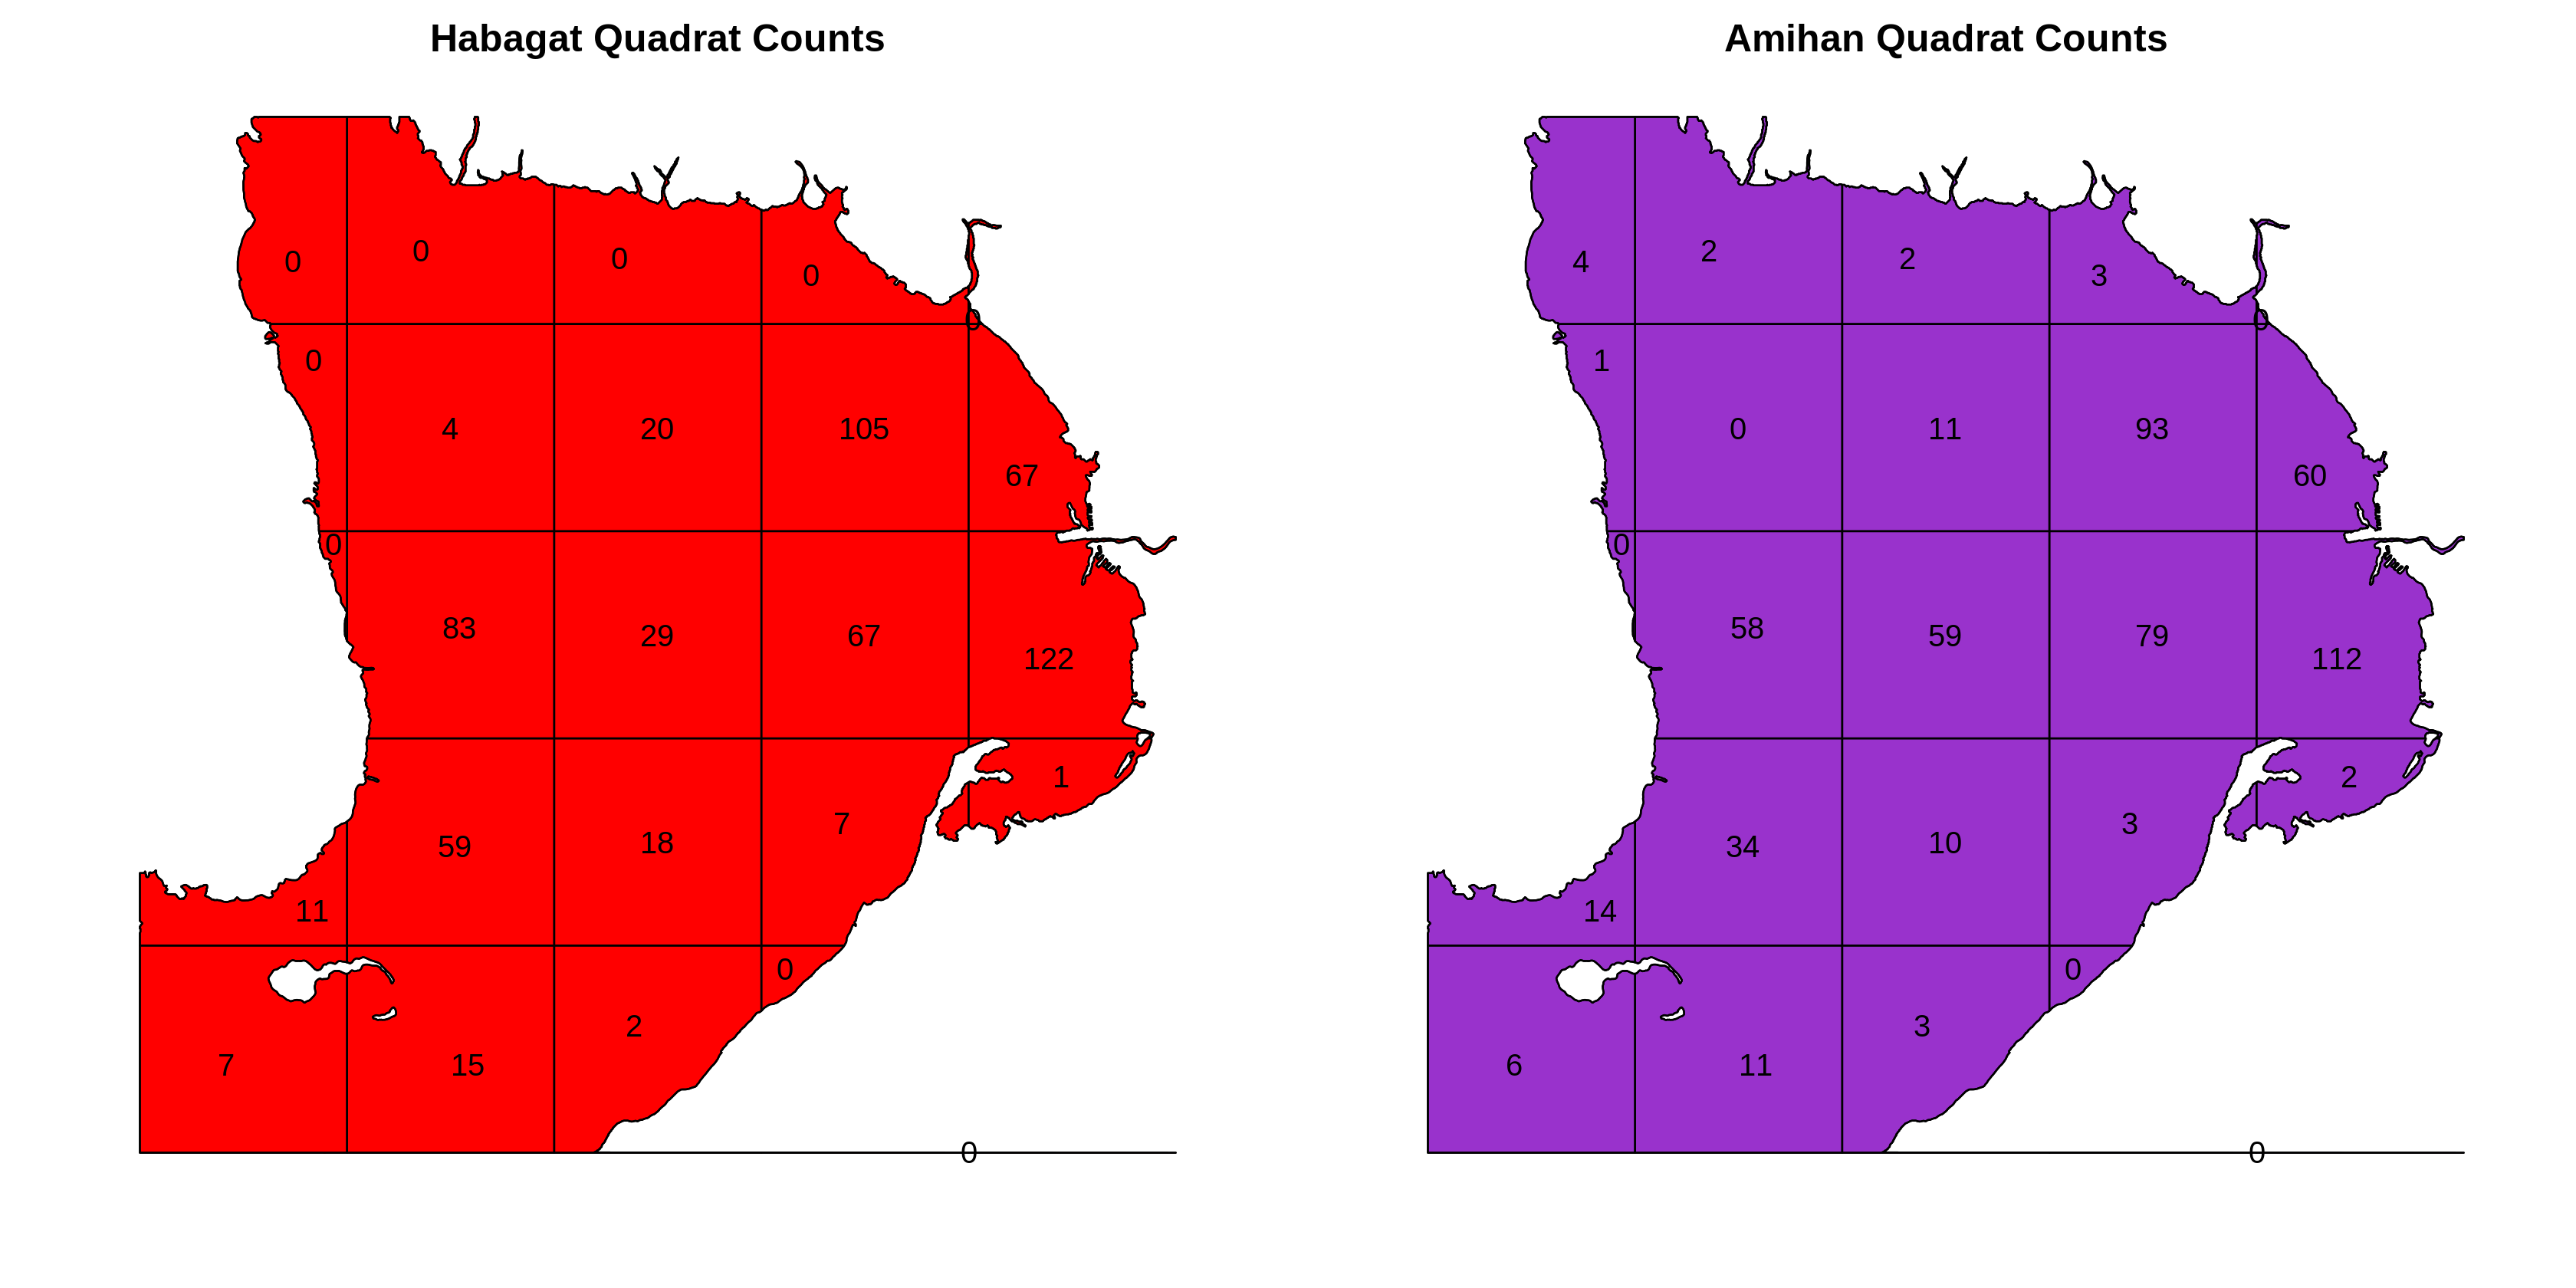

In [29]:
# Complete Spatial Randomness (CSR) Testing

# Quadrat Counting (Dividing the bay into a 5x5 grid)
q_count_habagat <- quadratcount(ppp_habagat, nx = 5, ny = 5)
q_count_amihan <- quadratcount(ppp_amihan, nx = 5, ny = 5)

# Chi-Squared Hypothesis Test
csr_test_habagat <- quadrat.test(q_count_habagat)
csr_test_amihan <- quadrat.test(q_count_amihan)

# Print the statistical results to the console
print("--- HABAGAT CSR TEST RESULTS ---")
print(csr_test_habagat)
print("--- AMIHAN CSR TEST RESULTS ---")
print(csr_test_amihan)

# Graph the quadrat grid overlaid with vessel counts
options(repr.plot.width = 28, repr.plot.height = 14)
par(mfrow=c(1,2), cex.main=2.5, mar=c(5, 2, 4, 0.5) + 0.1)

# Plot Habagat points and overlay the grid with counts
plot(ppp_habagat, main = "Habagat Quadrat Counts", pch = 20, cex = 0.5, col = "red")
plot(q_count_habagat, add = TRUE, cex = 2, col = "black", lwd = 2)

# Plot Amihan points and overlay the grid with counts
plot(ppp_amihan, main = "Amihan Quadrat Counts", pch = 20, cex = 0.5, col = "darkorchid")
plot(q_count_amihan, add = TRUE, cex = 2, col = "black", lwd = 2)

### **Mathematical Audit: Pearson Chi-Squared Goodness-of-Fit Test**

To formally evaluate the null hypothesis ($H_0$) of Complete Spatial Randomness (CSR), a quadrat counting method was applied, partitioning the non-convex observation window into a 5x5 grid to calculate observed versus expected vessel frequencies (DataCamp, n.d.). The statistical significance of spatial clustering was evaluated using the Pearson chi-squared goodness-of-fit test statistic:
**$$ X^2 = \sum_{i=1}^{k} \frac{(O_i - E_i)^2}{E_i} $$**

* **$X^2$**: The Pearson chi-squared test statistic.
* **$O_i$**: The observed number of vessel occurrences within quadrat $i$.
* **$E_i$**: The expected number of vessels in quadrat $i$ under the assumption of a homogeneous Poisson point process.

The analysis yielded $X^2$ values of 885.21 (Habagat) and 801.47 (Amihan), both resulting in $p$-values $< 2.2 \times 10^{-16}$. Because the $p$-value is drastically lower than the standard $\alpha = 0.05$ threshold, we strictly reject the null hypothesis of CSR. This mathematical rejection demonstrates that the spatial distribution of maritime traffic significantly deviates from complete spatial randomness, exhibiting strong clustering behavior, thereby validating the necessity to model the fleet distributions using an inhomogeneous Log-Gaussian Cox Process (LGCP) capable of incorporating latent environmental covariates (DataCamp, n.d.).


*(Note: The minor computational warnings regarding small expected counts arise strictly due to the geometric irregularities of the non-convex coastline intersecting the rigid 5x5 quadrat grid, creating marginal tiles with near-zero expected vessel occurrences; however, the massive magnitude of the test statistics ensures the rejection of $H_0$ is robust.)*

DAY 8